In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import os
import time
import cv2
import random
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from keras.models import Sequential
from keras.layers import Input, Dense, Conv2D, MaxPooling2D, Dropout, Flatten, BatchNormalization
from keras import callbacks, regularizers
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sn



In [2]:
path_train = "../Data/dataset_yawn_eye/train"
path_test = "../Data/dataset_yawn_eye/test/"
path_haar_faces = "../Data/dataset_yawn_eye/haarcascade/haarcascade_frontalface_default.xml"

IMG_SIZE = (145, 145)

labels = os.listdir(path_train)
labels.remove(".DS_Store")
labels.remove("Open")
labels.remove("Closed")


labels

['no_yawn', 'yawn']

### Import and resize image-data

In [3]:
"""def shuffle_data(x: list, y: list):
    n = len(y)

    for i in range(n):
        idx = random.randint(0, n - 1)
        
        x_elem = x.pop(idx)
        y_elem = y.pop(idx)
        
        x.append(x_elem)
        y.append(y_elem)

    return x, y
"""

def load_data(path_data):
    X = []
    y = []

    for label in os.listdir(path_data):
        # only yawning / not yawning in this case
        if label in labels:
            path = os.path.join(path_data, label)
            label_index = labels.index(label)
            print(label)

            for file in os.listdir(path):
                if not file.startswith('.'):
                    img_matrix = cv2.imread(os.path.join(path, file), cv2.IMREAD_GRAYSCALE)

                    face_cascade = cv2.CascadeClassifier(path_haar_faces)
                    found_faces = face_cascade.detectMultiScale(img_matrix, 1.3, 5)
                    
                    for (x_pos, y_pos, width, height) in found_faces:
                        img = cv2.rectangle(img_matrix, (x_pos, y_pos, width, height), (0, 255, 0), 2)

                        # get region of interest (only face)
                        img_matrix = img[y_pos : y_pos + height, x_pos : x_pos + width]
                    
                    try:
                        img_final = cv2.resize(img_matrix, IMG_SIZE)

                        X.append(img_final)
                        y.append(label_index)

                    except Exception as e:
                        print(e)
                        
    return X, y #shuffle_data(X, y)



In [5]:
"""img_matrix = []

face_cascade = cv2.CascadeClassifier(path_haar_faces)
found_faces = face_cascade.detectMultiScale(img_matrix, 1.3, 5)


for (x_pos, y_pos, width, height) in found_faces:
    img = cv2.rectangle(img_matrix, (x_pos, y_pos, width, height), (0, 255, 0), 2)

    # get region of interest (only face)
    img_matrix = img[y_pos : y_pos + height, x_pos : x_pos + width]"""

'img_matrix = []\n\nface_cascade = cv2.CascadeClassifier(path_haar_faces)\nfound_faces = face_cascade.detectMultiScale(img_matrix, 1.3, 5)\n\n\nfor (x_pos, y_pos, width, height) in found_faces:\n    img = cv2.rectangle(img_matrix, (x_pos, y_pos, width, height), (0, 255, 0), 2)\n\n    # get region of interest (only face)\n    img_matrix = img[y_pos : y_pos + height, x_pos : x_pos + width]'

In [6]:
x_train, y_train = load_data(path_train)
x_test, y_test = load_data(path_test)


print("x_train len: ", len(x_train))
print("y_train len: ", len(y_train))
print(f'labels : {list(set(y_train))}')
print(f'x_train-shape: ({ len(x_train) }, { len(x_train[0]) }, { len(x_train[0][0]) })')

print("Testdaten:")
print("x_train len: ", len(x_train))
print("y_train len: ", len(y_train))
print(f'labels : {list(set(y_train))}')
print(f'x_train-shape: ({ len(x_train) }, { len(x_train[0]) }, { len(x_train[0][0]) })')

no_yawn
OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

yawn
OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

no_yawn
yawn
OpenCV(4.7.0) 

#### Save image-data to binary files

In [7]:
npx = np.array(x_train)
dfx = pd.DataFrame(npx.reshape((npx.shape[0], npx.shape[1] * npx.shape[2])))

npy = np.array(y_train)
dfy = pd.DataFrame(npy)

dfx.to_csv("../Data/dataset_yawn_eye/preprocessed/x_train_face.csv")
dfy.to_csv("../Data/dataset_yawn_eye/preprocessed/y_train_face.csv")

npx = np.array(x_test)
dfx = pd.DataFrame(npx.reshape((npx.shape[0], npx.shape[1] * npx.shape[2])))

npy = np.array(y_test)
dfy = pd.DataFrame(npy)

dfx.to_csv("../Data/dataset_yawn_eye/preprocessed/x_test_face.csv")
dfy.to_csv("../Data/dataset_yawn_eye/preprocessed/y_test_face.csv")

### Read preprocessed CSV-data

In [4]:

def read_all_csv_data():
    path_x_csv = "../Data/dataset_yawn_eye/preprocessed/x_train_face.csv"
    path_y_csv = "../Data/dataset_yawn_eye/preprocessed/y_train_face.csv"
    path_x_csv_test = "../Data/dataset_yawn_eye/preprocessed/x_test_face.csv"
    path_y_csv_test = "../Data/dataset_yawn_eye/preprocessed/y_test_face.csv"

    x_read = pd.read_csv(path_x_csv, index_col = 0)
    y_read = pd.read_csv(path_y_csv, index_col = 0)
    x_read_test = pd.read_csv(path_x_csv_test, index_col = 0)
    y_read_test = pd.read_csv(path_y_csv_test, index_col = 0)

    x_train = x_read.values.reshape((len(x_read.index), IMG_SIZE[0], IMG_SIZE[1]))
    y_train = np.array(y_read).reshape(np.array(y_read).shape[0]).tolist()

    x_test = x_read.values.reshape((len(x_read.index), IMG_SIZE[0], IMG_SIZE[1]))
    y_test = np.array(y_read).reshape(np.array(y_read).shape[0]).tolist()

    del x_read
    del y_read
    del x_read_test
    del y_read_test

    return x_train, x_test, y_train, y_test


In [13]:
x_train, x_test, y_train, y_test = read_all_csv_data()


In [14]:
# normalize data
x_train = x_train.reshape((x_train.shape[0], x_train.shape[1] * x_train.shape[2]))
x_train = x_train.astype(float) / 255
x_test = x_test.reshape((x_test.shape[0], x_test.shape[1] * x_test.shape[2]))
x_test = x_test.astype(float) / 255

encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.fit_transform(y_test)

### Create and train simple MLP model

In [15]:
model_mlp = Sequential()
model_mlp.add(Input(shape=(IMG_SIZE[0] * IMG_SIZE[1],)))
model_mlp.add(Dense(256, activation="relu"))
model_mlp.add(Dense(128, activation="relu"))
model_mlp.add(Dense(len(set(y_train)), activation="softmax"))

model_mlp.summary()

model_mlp.compile(
    optimizer = "adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), 
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy()]
)

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_6 (Dense)             (None, 256)               5382656   
                                                                 
 dense_7 (Dense)             (None, 128)               32896     
                                                                 
 dense_8 (Dense)             (None, 2)                 258       
                                                                 
Total params: 5415810 (20.66 MB)
Trainable params: 5415810 (20.66 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [16]:
# early stopping callback

early_stopping = callbacks.EarlyStopping(
    monitor = "val_loss",
    mode = "min",
    min_delta = 0.01,
    patience = 3,
    restore_best_weights = True
)

In [17]:
# training of MLP
timer_start = time.time()

history = model_mlp.fit(
    x = x_train,
    y = y_train,
    validation_data = (x_test, y_test),
    # callbacks = [early_stopping],
    epochs = 50
)

timer_end = time.time()

print('\nGesamtlaufzeit: {:5.2f}s'.format(timer_end - timer_start))

Epoch 1/50
39/39 [==============================] - 1s 16ms/step - loss: 2.3084 - sparse_categorical_accuracy: 0.5318 - val_loss: 0.7218 - val_sparse_categorical_accuracy: 0.5187
Epoch 2/50
39/39 [==============================] - 0s 11ms/step - loss: 0.7611 - sparse_categorical_accuracy: 0.6148 - val_loss: 1.2001 - val_sparse_categorical_accuracy: 0.4992
Epoch 3/50
39/39 [==============================] - 0s 11ms/step - loss: 0.8073 - sparse_categorical_accuracy: 0.6173 - val_loss: 0.7403 - val_sparse_categorical_accuracy: 0.5847
Epoch 4/50
39/39 [==============================] - 0s 12ms/step - loss: 0.6135 - sparse_categorical_accuracy: 0.6669 - val_loss: 0.4983 - val_sparse_categorical_accuracy: 0.7695
Epoch 5/50
39/39 [==============================] - 0s 12ms/step - loss: 0.5273 - sparse_categorical_accuracy: 0.7435 - val_loss: 0.4713 - val_sparse_categorical_accuracy: 0.7663
Epoch 6/50
39/39 [==============================] - 0s 11ms/step - loss: 0.5644 - sparse_categorical_accu

In [18]:
predictions = model_mlp.predict(x_test)
y_pred = []

for i in predictions:
    y_pred.append(np.array(i).argmax())


y_test_transformed = encoder.inverse_transform(y_test)
y_pred_transformed = encoder.inverse_transform(y_pred)

mlp_report = classification_report(y_test_transformed, y_pred_transformed)


print(mlp_report)

39/39 [==============================] - 0s 2ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       615
           1       0.99      0.99      0.99       613

    accuracy                           0.99      1228
   macro avg       0.99      0.99      0.99      1228
weighted avg       0.99      0.99      0.99      1228



In [19]:
model_mlp.save("../Data/models/mlp_face_acc_99.h5")

/Users/simon/envs/datascience/lib/python3.11/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


# CNN

In [20]:
x_train_cnn, x_test_cnn, y_train_cnn, y_test_cnn = read_all_csv_data()

# normalize data
x_train_cnn = x_train_cnn.astype(float) / 255
x_train_cnn = x_train_cnn.reshape((x_train_cnn.shape[0], x_train_cnn.shape[1], x_train_cnn.shape[2], 1))
x_test_cnn = x_test_cnn.astype(float) / 255
x_test_cnn = x_test_cnn.reshape((x_test_cnn.shape[0], x_test_cnn.shape[1], x_test_cnn.shape[2], 1))

encoder_cnn = LabelEncoder()
y_train_cnn = encoder_cnn.fit_transform(y_train_cnn)
y_test_cnn = encoder_cnn.fit_transform(y_test_cnn)

### Create CNN architecture + train model

In [38]:
model_cnn = Sequential()
model_cnn.add(Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 1)))

model_cnn.add(Conv2D(filters=16, kernel_size=3, activation='relu'))
model_cnn.add(MaxPooling2D(pool_size=2))

model_cnn.add(Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
model_cnn.add(MaxPooling2D(pool_size=2))
model_cnn.add(BatchNormalization())
model_cnn.add(Dropout(0.5))

model_cnn.add(Conv2D(filters=64, kernel_size=3, activation='relu'))
model_cnn.add(MaxPooling2D(pool_size=2))
model_cnn.add(BatchNormalization())
model_cnn.add(Dropout(0.2))

model_cnn.add(Conv2D(filters=128, kernel_size=3, activation='relu'))
model_cnn.add(MaxPooling2D(pool_size=2))
model_cnn.add(BatchNormalization())
model_cnn.add(Dropout(0.25))

model_cnn.add(Flatten())

model_cnn.add(Dense(units=128, activation='relu'))
model_cnn.add(BatchNormalization())
model_cnn.add(Dropout(0.25))

model_cnn.add(Dense(units=len(set(y_train_cnn)),activation='softmax'))

model_cnn.compile(
    optimizer = "adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), 
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy()]
)

model_cnn.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_8 (Conv2D)           (None, 143, 143, 16)      160       
                                                                 
 max_pooling2d_8 (MaxPoolin  (None, 71, 71, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_9 (Conv2D)           (None, 71, 71, 32)        4640      
                                                                 
 max_pooling2d_9 (MaxPoolin  (None, 35, 35, 32)        0         
 g2D)                                                            
                                                                 
 batch_normalization_4 (Bat  (None, 35, 35, 32)        128       
 chNormalization)                                                
                                                      

In [11]:
# early stopping callback

early_stopping_cnn = callbacks.EarlyStopping(
    monitor = "val_loss",
    mode = "min",
    min_delta = 0.02,
    patience = 5,
    restore_best_weights = True
)

In [22]:
timer_start = time.time()

history_cnn = model_cnn.fit(
    x_train_cnn,
    y_train_cnn,
    validation_data=(x_test_cnn, y_test_cnn), 
    # callbacks=[early_stopping_cnn],
    epochs = 50
)

timer_end = time.time()


print('\nGesamtlaufzeit: {:5.3f}s'.format(timer_end - timer_start))

Epoch 1/50
39/39 [==============================] - 23s 582ms/step - loss: 0.7041 - sparse_categorical_accuracy: 0.5171 - val_loss: 0.6929 - val_sparse_categorical_accuracy: 0.5057
Epoch 2/50
39/39 [==============================] - 22s 555ms/step - loss: 0.6799 - sparse_categorical_accuracy: 0.5619 - val_loss: 0.6242 - val_sparse_categorical_accuracy: 0.6547
Epoch 3/50
39/39 [==============================] - 22s 565ms/step - loss: 0.6516 - sparse_categorical_accuracy: 0.6173 - val_loss: 0.5978 - val_sparse_categorical_accuracy: 0.6515
Epoch 4/50
39/39 [==============================] - 22s 555ms/step - loss: 0.5910 - sparse_categorical_accuracy: 0.6621 - val_loss: 0.5719 - val_sparse_categorical_accuracy: 0.7028
Epoch 5/50
39/39 [==============================] - 22s 578ms/step - loss: 0.5660 - sparse_categorical_accuracy: 0.6792 - val_loss: 0.5348 - val_sparse_categorical_accuracy: 0.7443
Epoch 6/50
39/39 [==============================] - 22s 572ms/step - loss: 0.5364 - sparse_cate

In [23]:
# predicts

predictions_cnn = model_cnn.predict(x_test_cnn)
y_pred_cnn = []
for i in predictions_cnn:
    y_pred_cnn.append(np.array(i).argmax())

y_test_cnn_transformed = encoder_cnn.inverse_transform(y_test_cnn)
y_pred_cnn_transformed = encoder_cnn.inverse_transform(y_pred_cnn)

report_cnn = classification_report(y_test_cnn_transformed, y_pred_cnn_transformed)
print(report_cnn)

39/39 [==============================] - 5s 117ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       615
           1       1.00      0.99      1.00       613

    accuracy                           1.00      1228
   macro avg       1.00      1.00      1.00      1228
weighted avg       1.00      1.00      1.00      1228



In [24]:
model_cnn.save("../Data/models/cnn_face_acc_100.h5")

/Users/simon/envs/datascience/lib/python3.11/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [25]:
y_pred_cnn = []
for i in predictions_cnn:
    y_pred_cnn.append(np.array(i).argmax())

y_test_cnn_retransformed = encoder_cnn.inverse_transform(y_test_cnn)
y_pred_cnn_retransformed = encoder_cnn.inverse_transform(y_pred_cnn)

### Evaluation

In [26]:
sorted_labels = sorted(list(set(y_test_cnn_retransformed.tolist())))
matrix_cnn = confusion_matrix(y_test_cnn_transformed, y_pred_cnn_transformed, normalize = "true")

misclassifications = []
for i in range(len(matrix_cnn[0]) - 1):
    for j in range(len(matrix_cnn[0]) - 1):
        if matrix_cnn[i][j] > 0.2 and i != j:
            misclassifications.append((sorted_labels[i], sorted_labels[j], matrix_cnn[i][j]))

for x in misclassifications:
    print(x)

In [31]:
def show_confusion_matrix(y_test, y_pred, path="../imgs/cnn/"):
    """
    prints the normalized confusion matrix in a seaborn heatmap
    """
    matrix = confusion_matrix(y_test, y_pred, normalize='true')
    sortedLabels = sorted(list(set(y_test.tolist())))

    plt.figure(figsize=(7, 7))
    sn.heatmap(matrix, xticklabels=sortedLabels, yticklabels=sortedLabels, annot=True, cmap="coolwarm")

    plt.savefig(os.path.join(path, 'confusion_matrix.svg'))

    plt.show()


def show_epoch_history(history, path="../imgs/cnn/"):
    history_df = pd.DataFrame(history.history)

    plot = history_df.loc[:,['loss', 'val_loss', 'sparse_categorical_accuracy', 'val_sparse_categorical_accuracy']].plot()
    fig = plot.get_figure()

    fig.savefig(os.path.join(path, 'epoch_history.svg'))


def evaluate_neural_network(y_test, y_pred, path="../imgs/cnn/"):
    """
    prints the precision, recall and f1-score of each label in a seaborn bar plot
    """
    report_raw = classification_report(y_test, y_pred, output_dict=True)
    report = []

    for i in sorted(report_raw.keys()):
        if i not in ['accuracy', 'macro avg', 'weighted avg']:
            report.append([report_raw[i]['precision'], 'precision', i])
            report.append([report_raw[i]['f1-score'], 'f1-score', i])
            report.append([report_raw[i]['recall'], 'recall', i])

    report_df = pd.DataFrame(data = report, columns = ['value', 'type', 'class'])

    plt.figure(figsize = (5, 8))
    plt.title("precision, recall and f1-score of each class")
    sn.barplot(data = report_df, y = 'class', x = 'value', hue = 'type')

    plt.savefig(os.path.join(path, 'evaluation.svg'))

    plt.show()



-	Wann sagt das System „Müdigkeit erkannt“?
o	Relevante Punkte bei der Implementierung?
o	Wie berechnet sich das „verdict“?
	Aus Gähnen, Sekundenschlaf, starren, … ???
	Implementierung der KOMPONENTEN!!!
-	Was passiert dann?


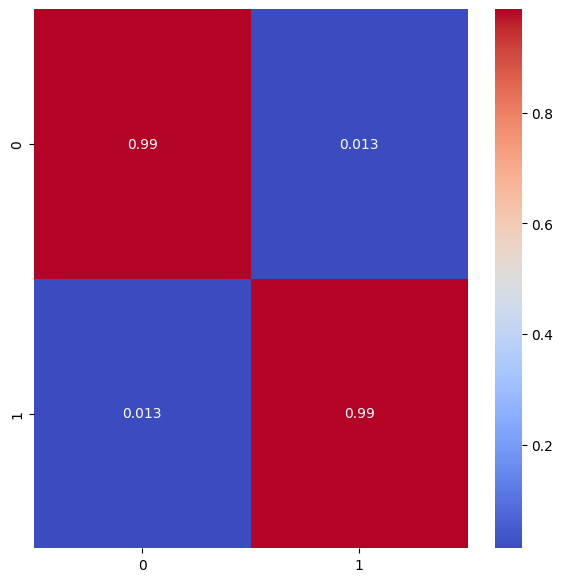

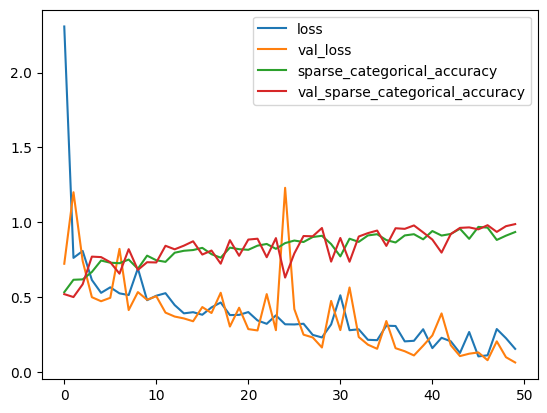

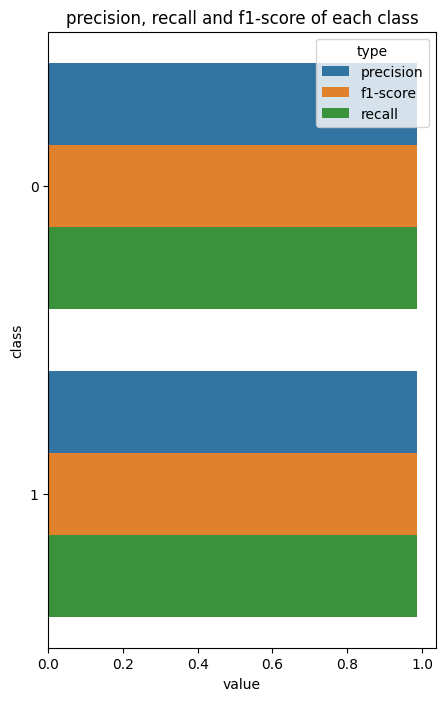

In [32]:
# for mlp
show_confusion_matrix(y_test, y_pred, "../imgs/mlp/")
show_epoch_history(history, "../imgs/mlp/")
evaluate_neural_network(y_test, y_pred, "../imgs/mlp/")


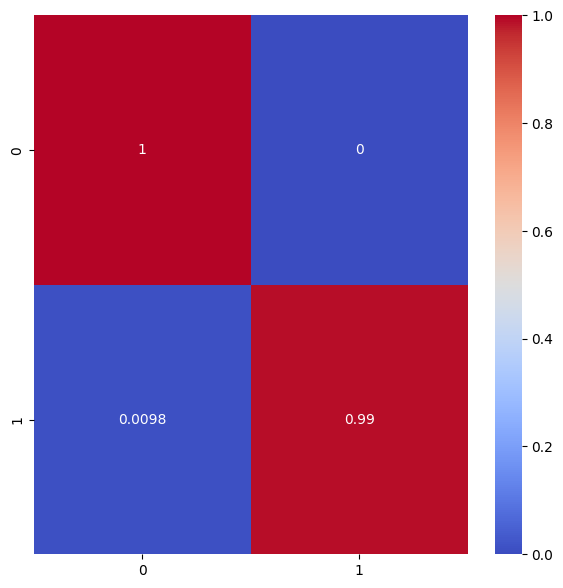

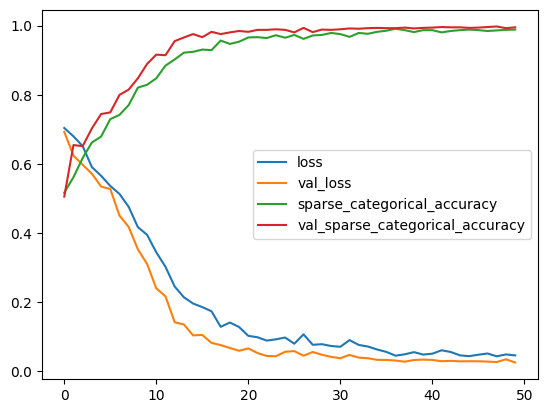

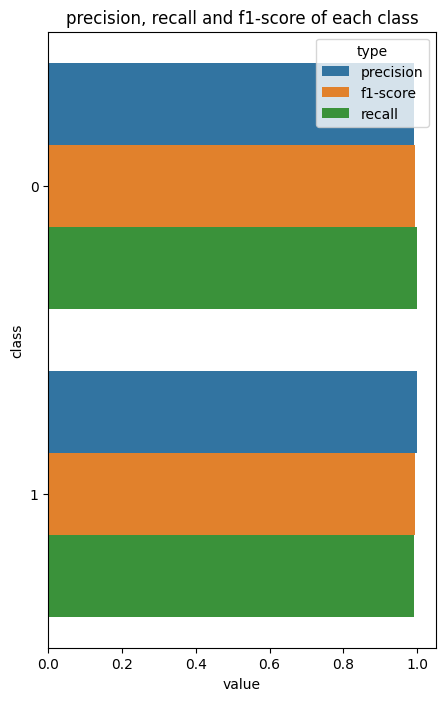

In [33]:
# for cnn
show_confusion_matrix(y_test_cnn, y_pred_cnn)
show_epoch_history(history_cnn)
evaluate_neural_network(y_test_cnn, y_pred_cnn)


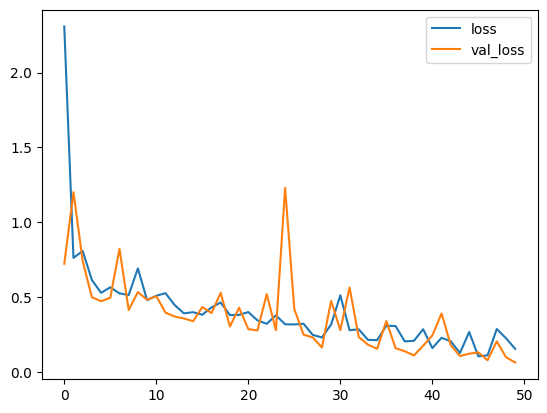

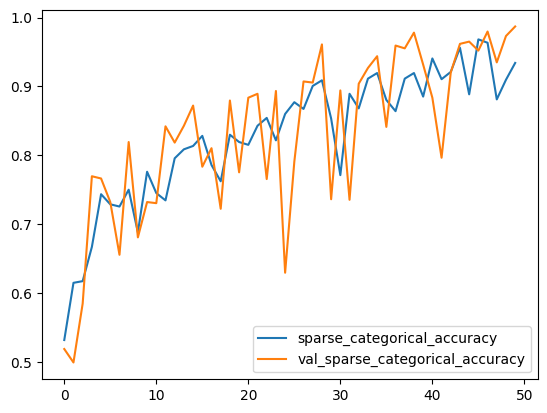

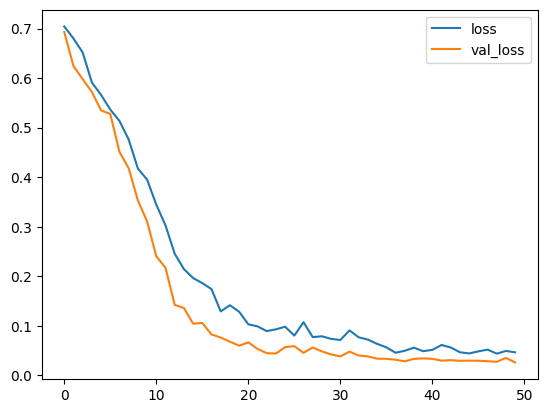

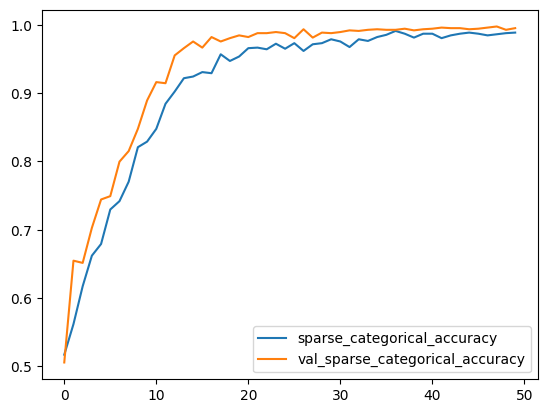

In [36]:


def show_epoch_history_separate(history, path="../imgs/cnn/"):
    history_df = pd.DataFrame(history.history)

    plot = history_df.loc[:, ['loss', 'val_loss']].plot()
    fig1 = plot.get_figure()
    fig1.savefig(os.path.join(path, 'epoch_history_loss.svg'))


    plot2 = history_df.loc[:, ['sparse_categorical_accuracy', 'val_sparse_categorical_accuracy']].plot()
    fig2 = plot2.get_figure()
    fig2.savefig(os.path.join(path, 'epoch_history_accuracy.svg'))


show_epoch_history_separate(history, "../imgs/mlp/")
show_epoch_history_separate(history_cnn)
